# Conditional generative super resolution
Compare direct reconstruction, adversarial learning, a conditional VAE and diffusion
on identical 256px held-out photographs. [Measured results](../docs/modern_results.md)
and [complete protocol](../docs/12_generative_restoration.md). Every sample is included;
there is no closest-to-target selection.

In [1]:
from pathlib import Path
import json
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
root = Path.cwd()
while not (root / 'pyproject.toml').exists() and root != root.parent:
    root = root.parent
sys.path.insert(0, str(root / 'src'))
def evidence(study):
    return json.loads((root / 'results' / 'reference' / study / 'metrics.json').read_text())
plt.rcParams.update({'figure.figsize': (7, 4), 'axes.spines.top': False, 'axes.spines.right': False})

from io import BytesIO
from PIL import Image as PILImage
from IPython.display import Image as NotebookImage, display
def preview(path):
    # Compressed display preview; full-resolution scientific figures remain in assets.
    with PILImage.open(path) as picture:
        picture.thumbnail((760,760))
        buffer = BytesIO()
        picture.convert('RGB').save(buffer,format='JPEG',quality=90)
    display(NotebookImage(data=buffer.getvalue()))

In [2]:
task = 'super_resolution'
summary = json.loads((root/'assets/modern_summary.json').read_text())
expected_methods = {'baseline','l1','gan','cvae','diffusion'} | (
    {'ddcolor','ct2','bigcolor'} if task == 'colorization' else {'swinir','realesrgan'})
assert {row['method'] for row in summary[task]['comparisons']} == expected_methods
pd.DataFrame(summary[task]['comparisons'])

,method,pipeline,fitted checkpoints,samples per seed,psnr,psnr seed SD,ssim,ssim seed SD,lpips,lpips seed SD,data_consistency_l1,data_consistency_l1 seed SD,RGB draw dispersion
0,baseline,local,0,1,24.256703,NaN,0.678329,NaN,0.461792,NaN,0.009184,NaN,NaN
1,l1,local,2,1,26.410908,0.112345,0.763745,0.000784,0.193592,0.007292,0.002764,0.000580,NaN
2,gan,local,2,1,25.401749,0.033013,0.728670,0.001136,0.235399,0.001852,0.003352,0.000069,NaN
3,cvae,local,2,4,26.345986,0.089272,0.763229,0.000900,0.188218,0.003335,0.003107,0.000495,0.000170
4,diffusion,local,2,4,23.881367,0.003465,0.658042,0.001642,0.148615,0.000889,0.001470,0.000059,0.037829
5,swinir,external,1,1,27.132186,NaN,0.787428,NaN,0.223292,NaN,0.001921,NaN,NaN
6,realesrgan,external,1,1,23.026612,NaN,0.653472,NaN,0.206361,NaN,0.022798,NaN,NaN


## Pair images, then distinguish samples from training seeds
An image bootstrap conditions on the fitted checkpoints. Averaging four samples
from one model does not produce four training seeds. Both SR CVAE seeds fit their complete model independently.

In [3]:
pd.DataFrame(summary[task]['paired'])

,method,metric,difference vs baseline,image CI lower,image CI upper
0,l1,psnr,2.154205,2.050086,2.261849
1,l1,lpips,-0.268199,-0.273376,-0.262956
2,gan,psnr,1.145046,1.076612,1.215563
3,gan,lpips,-0.226393,-0.230640,-0.221943
4,cvae,psnr,2.089283,1.985281,2.192897
5,cvae,lpips,-0.273573,-0.278889,-0.268217
6,diffusion,psnr,-0.375336,-0.463046,-0.285459
7,diffusion,lpips,-0.313177,-0.320488,-0.305425
8,swinir,psnr,2.875483,2.743986,3.011519
9,swinir,lpips,-0.238500,-0.244900,-0.232028


## Compare against a trained predictor and inspect score distributions
A generative method must also be compared with a strong direct predictor.
No examples are filtered out, and all methods use the same numerical scoring floor. Report medians and quartiles as well as mean PSNR: image content and texture strongly affect reconstruction difficulty.

In [4]:
pd.DataFrame(summary[task]['paired_direct'])

,method,metric,difference vs L1 + features,image CI lower,image CI upper
0,gan,psnr,-1.009159,-1.063090,-0.959450
1,gan,lpips,0.041807,0.039469,0.043936
2,cvae,psnr,-0.064922,-0.072334,-0.058106
3,cvae,lpips,-0.005374,-0.005742,-0.005011
4,diffusion,psnr,-2.529541,-2.577324,-2.482979
5,diffusion,lpips,-0.044978,-0.050809,-0.039550
6,swinir,psnr,0.721278,0.680738,0.764314
7,swinir,lpips,0.029699,0.026904,0.032607
8,realesrgan,psnr,-3.384295,-3.500000,-3.270237
9,realesrgan,lpips,0.012768,0.007825,0.017811


In [5]:
pd.DataFrame(summary[task]['image_distributions'])

,method,images,PSNR median,PSNR Q25,PSNR Q75,PSNR above 60dB
0,baseline,400,23.935386,22.072654,26.206874,0
1,l1,400,26.277699,23.803186,28.662629,0
2,gan,400,25.082805,23.072373,27.458854,0
3,cvae,400,26.184610,23.768552,28.572242,0
4,diffusion,400,23.771611,21.368191,25.864199,0
5,swinir,400,26.895234,24.341199,29.404984,0
6,realesrgan,400,22.904130,20.940561,24.945523,0


## Resource context
Inference parameter counts include frozen encoders. Summed epoch times include validation and exclude initialization/export; the colorization CVAE additionally depends on its shared direct predictor. Metric-inclusive inference times come from concurrent reference workloads, not a controlled latency benchmark.

In [6]:
pd.DataFrame(summary[task]['resources'])

,method,inference parameters (M),epochs per fitted seed,local training images,selection images,training crop,summed epoch hours,seconds per 400 images including metrics
0,baseline,0.000000,0,0,0,NaN,NaN,1.340841
1,l1,2.415795,60,16000,128,128.0,1.826312,2.433910
2,gan,2.415795,60,16000,128,128.0,2.068826,2.742977
3,cvae,2.808435,60,16000,128,128.0,1.073845,1.388480
4,diffusion,2.491203,60,16000,128,128.0,0.873987,41.770435
5,swinir,11.900199,0,0,0,NaN,NaN,9.867105
6,realesrgan,16.697987,0,0,0,NaN,NaN,10.999436


## Does the latent variable affect the output?
Compare training posterior KL, prior-based validation and held-out RGB draw dispersion. Tiny KL and negligible sample differences are consistent with weak latent use. They do not prove a mutual-information claim, and reconstruction alone does not demonstrate useful conditional generation.

In [7]:
pd.DataFrame(summary[task]['latent_diagnostics'])

,seed,selected epoch,selected-epoch posterior KL,final posterior KL,selected prior validation loss,test RGB draw dispersion
0,0,59,0.000261,0.000256,0.079635,0.000178
1,1,58,0.000305,0.000304,0.078579,0.000163


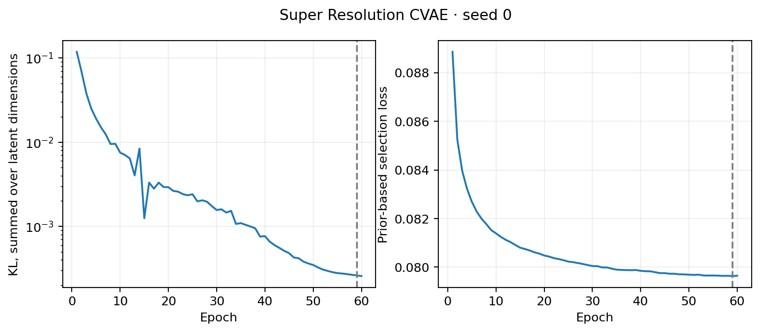

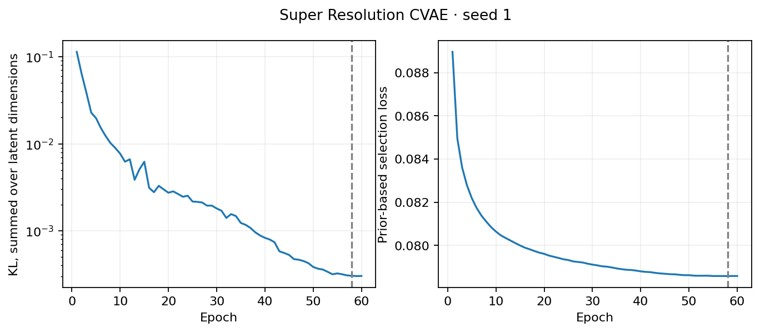

In [8]:
for path in sorted(root.glob(f'assets/generative_{task}_cvae_seed*_latent.png')):
    preview(path)

## Verify the Gaussian KL independently
The conditional prior is available at inference. The posterior observes the training
target and must never enter test inference. The feature term means the entire training
objective is not an exact evidence lower bound.

In [9]:
import torch
from learning_lab.generative import gaussian_kl
torch.set_num_threads(2)
qmean, pmean = torch.tensor([[1.,-1.]]), torch.zeros(1,2)
qlog, plog = torch.zeros(1,2), torch.zeros(1,2)
actual = gaussian_kl(qmean,qlog,pmean,plog)
expected = torch.distributions.kl_divergence(
    torch.distributions.Normal(qmean,(qlog/2).exp()),
    torch.distributions.Normal(pmean,(plog/2).exp())).sum(1).mean()
torch.testing.assert_close(actual,expected)
print('Independent analytic KL:',actual.item())

Independent analytic KL: 1.0


## Velocity prediction and the conditional observation
Under the cosine schedule, velocity and the noisy target form an invertible rotation.
The observation remains separate from the diffused field. SR conditions on an actual
bicubic LR observation; colorization conditions only on lightness.

In [10]:
from learning_lab.generative import alpha_schedule, observation, reconstruct
a = alpha_schedule()[500]
rng = torch.Generator().manual_seed(7)
clean = torch.randn(2,3,16,16,generator=rng)
noise = torch.randn(clean.shape,generator=rng)
noisy = a.sqrt()*clean + (1-a).sqrt()*noise
velocity = a.sqrt()*noise - (1-a).sqrt()*clean
torch.testing.assert_close(a.sqrt()*noisy-(1-a).sqrt()*velocity,clean)
rgb = torch.rand(2,3,32,32,generator=rng)
c, field = observation(rgb,task)
torch.testing.assert_close(reconstruct(c,field,task),rgb,atol=2e-5,rtol=0)
print('Velocity identity and observation reconstruction verified.')

Velocity identity and observation reconstruction verified.


generative_super_resolution_baseline_baseline_0_gallery.png


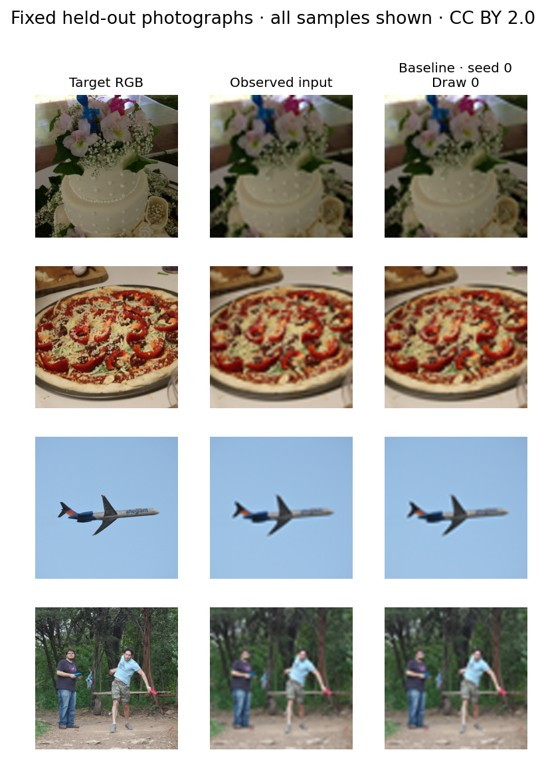

generative_super_resolution_cvae_cvae_0_gallery.png


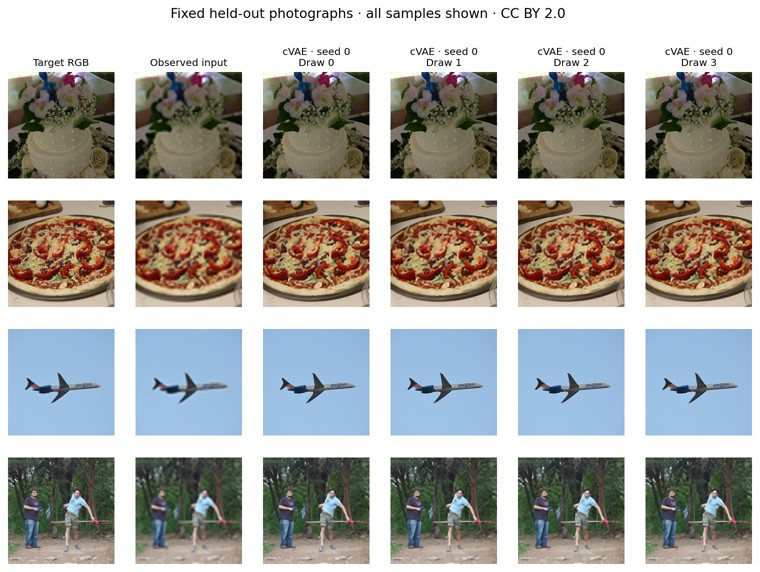

generative_super_resolution_cvae_cvae_1_gallery.png


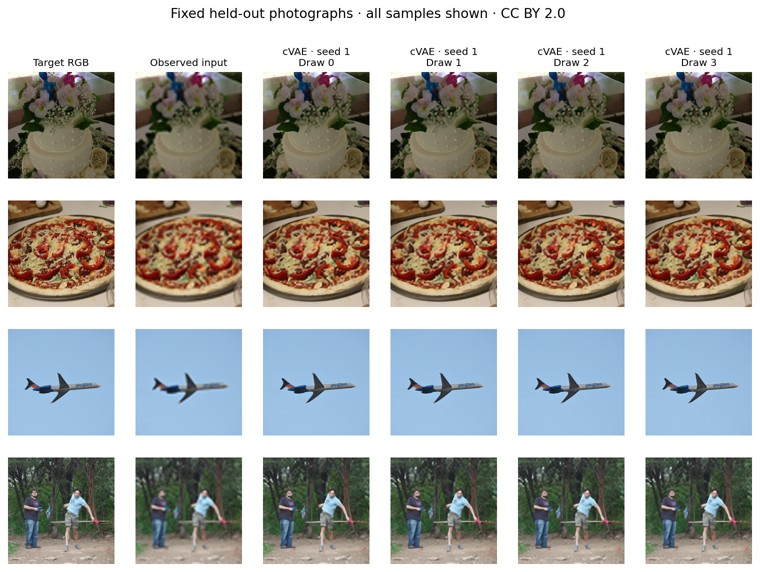

generative_super_resolution_diffusion_diffusion_0_gallery.png


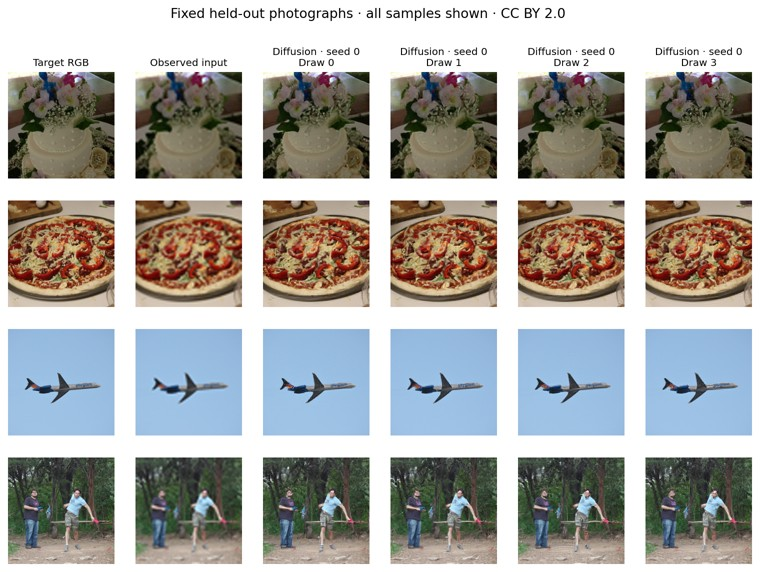

generative_super_resolution_diffusion_diffusion_1_gallery.png


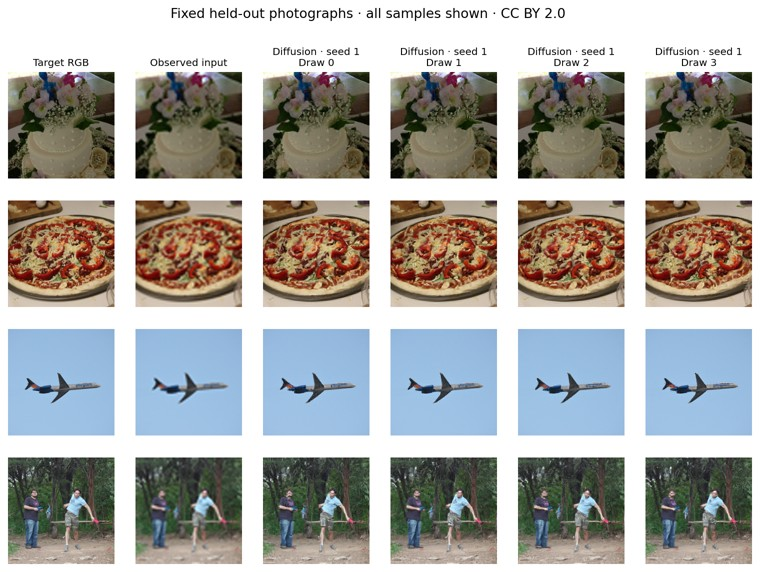

generative_super_resolution_gan_gan_0_gallery.png


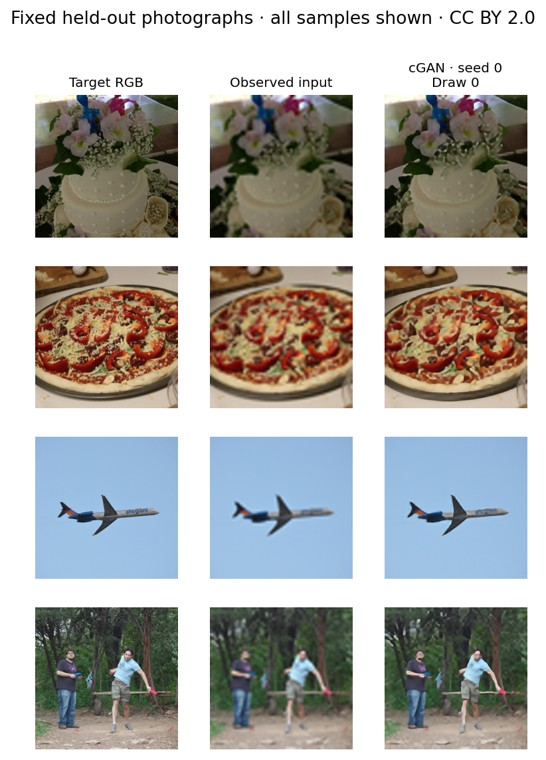

generative_super_resolution_gan_gan_1_gallery.png


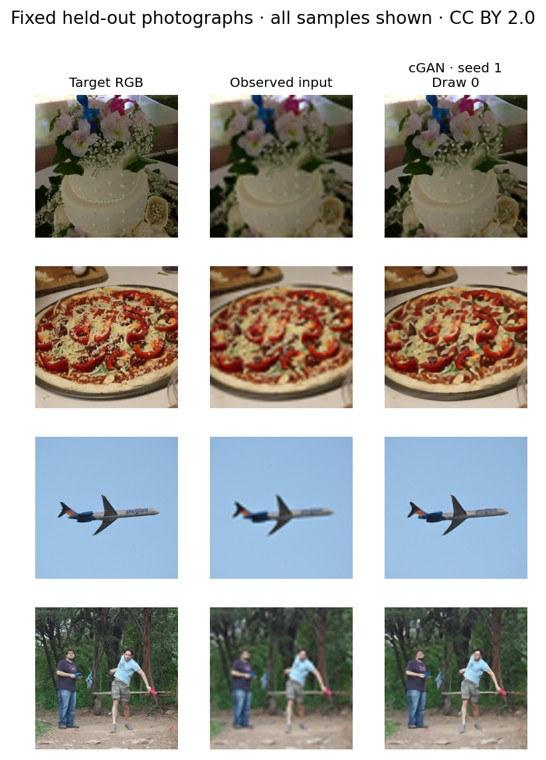

generative_super_resolution_l1_l1_0_gallery.png


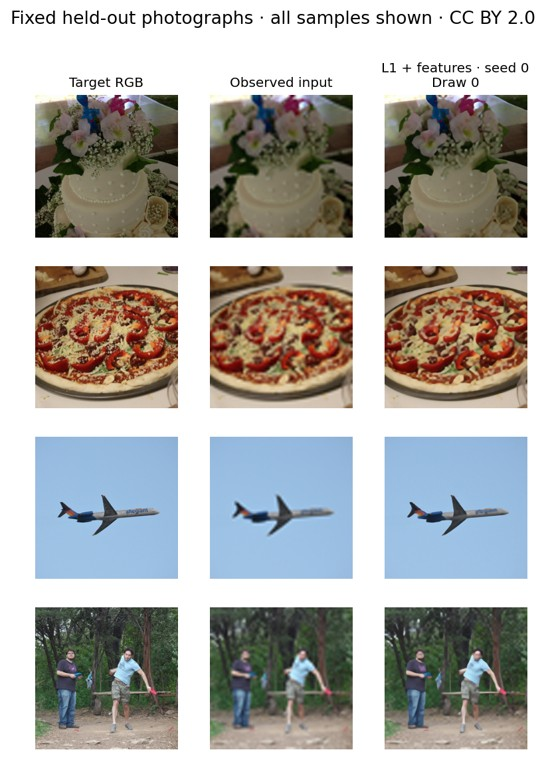

generative_super_resolution_l1_l1_1_gallery.png


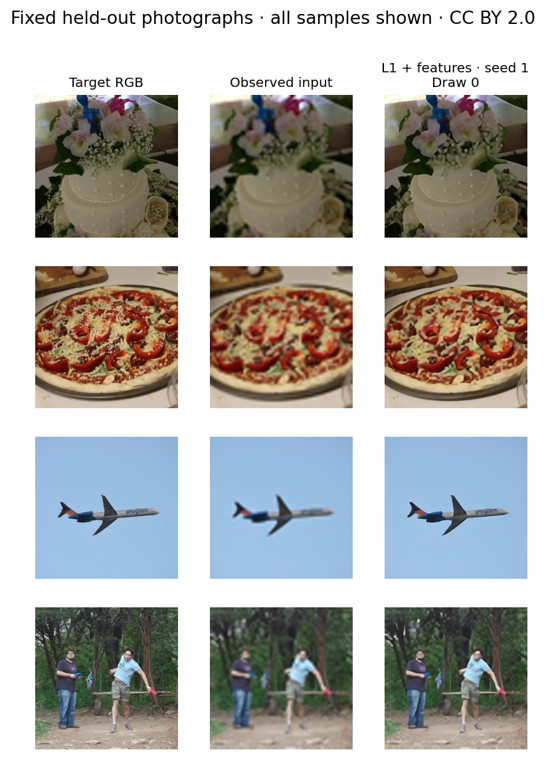

external_swinir_swinir_0_gallery.png


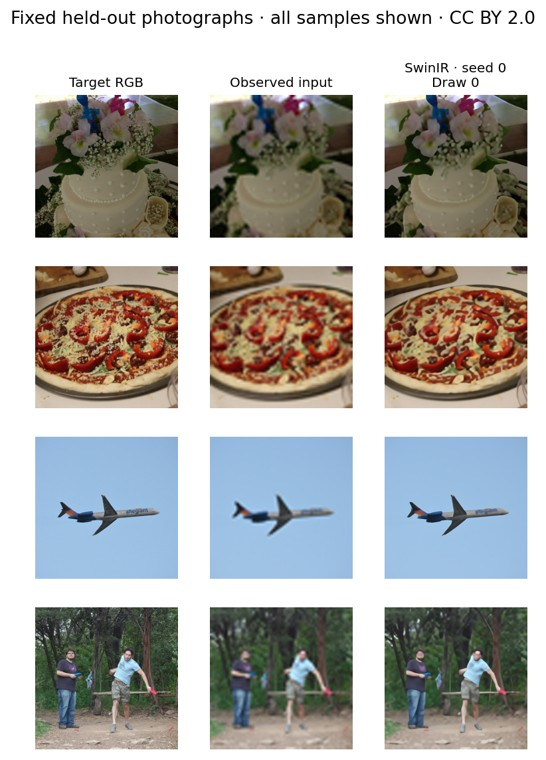

external_realesrgan_realesrgan_0_gallery.png


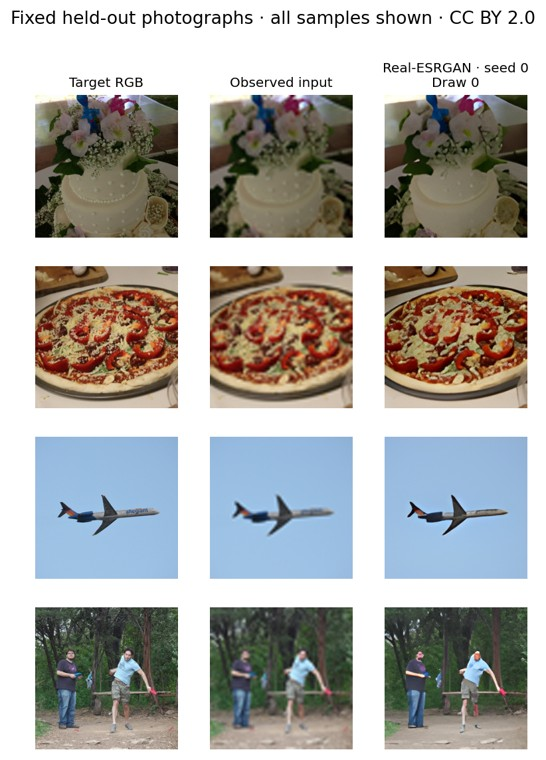

In [11]:
from IPython.display import Image,display
figures = sorted(root.glob(f'assets/generative_{task}_*_*_gallery.png'))
references = ['ddcolor','ct2','bigcolor'] if task == 'colorization' else ['swinir','realesrgan']
for method in references:
    figures += sorted(root.glob(f'assets/external_{method}_*_gallery.png'))
assert figures
for path in figures:
    print(path.name)
    preview(path)

## Worked answer
Why can an adversarial or diffusion output look plausible but have lower PSNR? The
observation does not uniquely determine the target. Plausible alternatives can differ
from its pixels. This does not excuse weak outputs: inspect LPIPS, observation
consistency, fixed galleries and RGB sample dispersion together. Near-zero VAE
dispersion indicates limited stochastic behavior even when reconstruction is strong.
Neither these experiments nor their two local seeds establish a general method ranking.

## Degradation mismatch
Frozen transformer and adversarial references are also tested under shared blur and LR noise/JPEG compression. No test tuning or adaptation. Their bicubic reprojection metric is not a complete forward likelihood for these stressors.

In [12]:
shifted = evidence('sr_shift')
pd.DataFrame([{'model':r['method'],'degradation':r['degradation'],**{k:r[k]['mean'] for k in ['psnr','ssim','lpips']}} for r in shifted['rows']])

,model,degradation,psnr,ssim,lpips
0,bicubic,bicubic,24.256703,0.678328,0.461792
1,swinir,bicubic,27.132188,0.787428,0.223291
2,realesrgan,bicubic,23.025241,0.653453,0.206339
3,bicubic,blur,23.799717,0.656129,0.494368
4,swinir,blur,25.599213,0.736592,0.361073
5,realesrgan,blur,23.049092,0.649826,0.207099
6,bicubic,noise_jpeg,22.594651,0.586453,0.638147
7,swinir,noise_jpeg,22.497685,0.578156,0.530782
8,realesrgan,noise_jpeg,21.785415,0.590124,0.258239


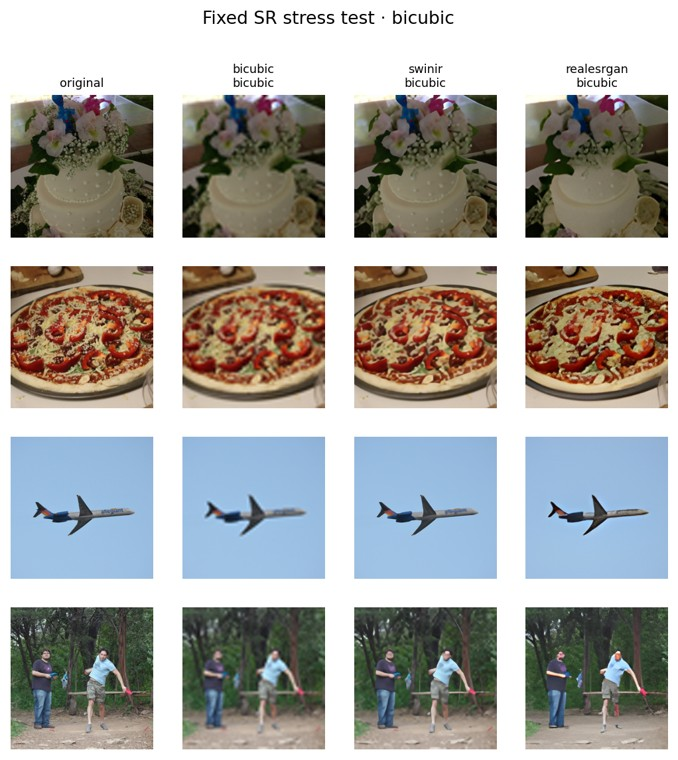

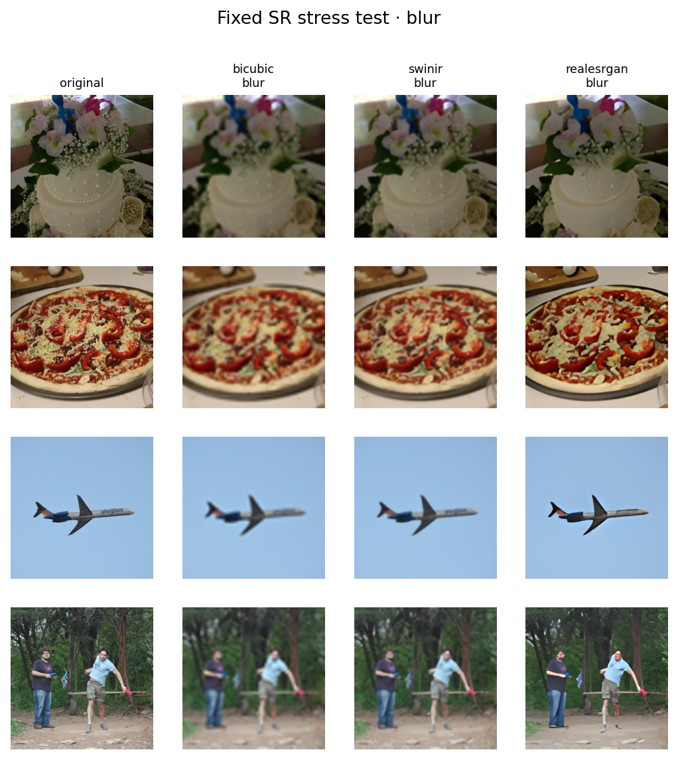

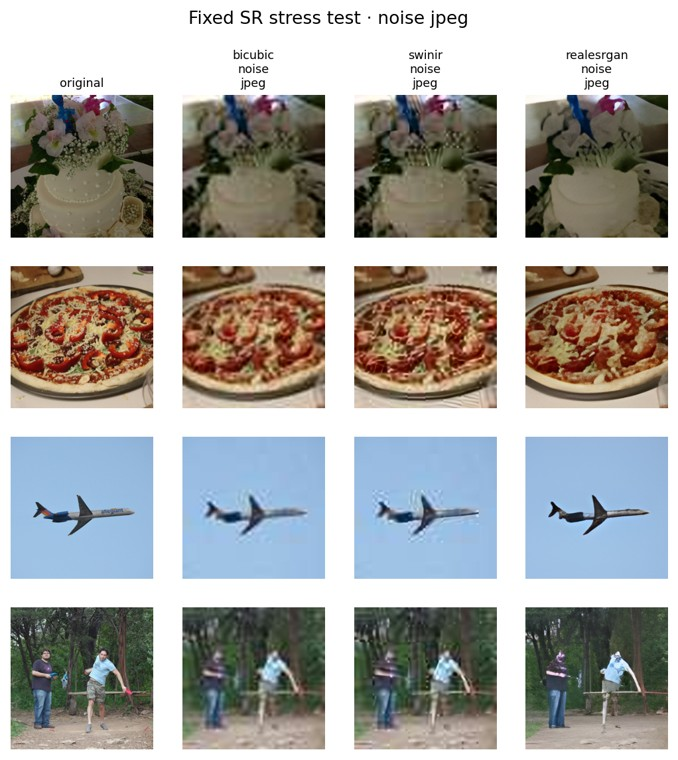

In [13]:
for condition in ['bicubic','blur','noise_jpeg']:
    preview(root/f'assets/sr_shift_{condition}_gallery.png')